LECTURE - 1

now i am going to do some derivative 


In [2]:
import numpy as np 
import matplotlib.pyplot as plt 
import math

In [3]:
def f(x):
    return 3*x**2 - 4*x + 5
    

In [4]:
f(3)

20

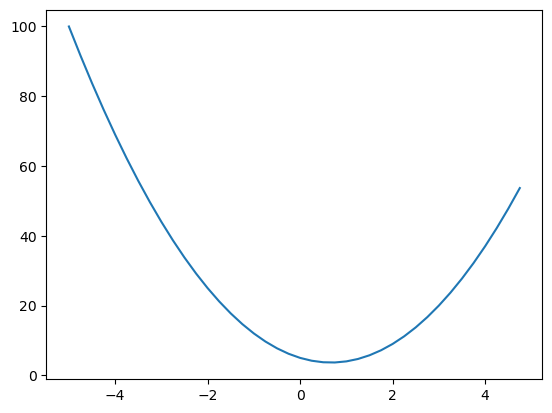

In [5]:
x_axis = np.arange(-5 , 5, 0.25)
ys = f(x_axis)
plt.plot(x_axis,ys)

i think by adding h the loss fuction will increase by some value it will 20 plus lets see what happens yep i ran it and the output is plus 20 but why did it happen because i nudged x it increased the loss function when you plug in the values to derivative why derivative?The derivative tells you the exact slope at your current position. You don't need to try anything — the math tells you instantly which direction is downhill and how steep it is. One calculation, perfect direction, every time

In [6]:
h = 0.001
x = 3.0
(f(x+h)-f(x))/h

14.00300000000243

In [7]:
a = 2
b = -3
c= 10
d = a*b + c
print(d)

4


In [8]:
h = 0.00001
a = 2
b = -3
c= 10
d1 = a*b + c
c += h
d2 = a*b + c
print(d1)
print(d2)
print((d2-d1)/h)
(f(d1)-f(d2))/h

4
4.00001
0.9999999999621422


-20.00002999835715

19:19 mins Now we need data structures to maintain the massive neural networks or the value objects.. so first question what kind of data structure is most suited for expressions like this first thing that pops my mind is expression tree the correct answer is tensor because it can hold dimensional array as expressions 

In [2]:
class Value:

    def __init__(self,data, _children=(),_operator=" ", _label = ''): #tupple for conv and maintain it in class as I put grad over here not sure whether it is correct or not 
        self.data = data#scalar value and wraps it 
        self.grad = 0.0  #It maintains the derivative of L with respect to that Value previously it is is 0 now i am changing it
        self._backward = lambda: None    #it will do the chain rule for but by default it doesnt do anything 
        self._prev = set(_children)
        self._operator = _operator #set stores the string directly 
        self._label = _label
    def __repr__(self):
        return f"Value(data = {self.data})" #need to check what this repr function is ahh it just control what python showss when you print a Value object or just type it in a cell

    def __add__ (self , other ):
        other = other if isintance(other, Value) else Value(other) #we are doing so that we can add for a+1 instead of throwing a value error if other is not not instance of value we will simply wrap up it and add
        outcome = Value(self.data + other.data , (self, other),'+' ) #feeding the children of this which is self and other 
        def _backward():
            self.grad += 1.0 * outcome.grad #+= is written so that the over write condition is avoided because intially self and one are the same thats why iot stays at one 
            other.grad += 1.0 * outcome.grad # += is written to accumulate
        outcome._backward  = _backward
        return outcome

    def __mul__ (self , other):
        other = other if isintance(other, Value) else Value(other) #
        outcome = Value(self.data * other.data , (self,other) , "*")
        def _backward():
            seld.grad += other.data* outcome.grad
            other.grad += self.data * outcome.grad
        outcome._backward = _backward
        return outcome

    def __neg__(self):
        return self*-1   
        
    def __sub__(self,other):
        return self + (-other)
        
    def __rmul__(self,other):
        return self*other
        
    def __rdiv__(self , other):#aa/b = a * 1/b = a*b**-1
        return self * other**-1

    def __pow__(self):#
        assert isinstance(other,(int,float))
        out = Value(self.data ** other , (self,))

        def _backward():
            self.grad = other*self.data **(other -1) * out.grad 
        out._backward = _backward     
        
    def tanh(self):#     
        x = self.data
        t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
        outcome = Value(t, (self,), 'tanh')

        def _backward():
            self.grad += (1- t**2) * out.grad #why is it like this 1-t2 is the local derivative of tanh 
        outcome._backward = _backward 
        return outcome


    def exp(self):#
        x = self.data
        out = Value(math.exp(x) , (self, ),'exp')

        def _backward():
            self.grad += out.data * out.grad  
        outcome._backward = _backward
        return outcome
        
    def backward(self):
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)
        self.grad = 1.0
        
        for node in reversed(topo):
            node._backward()
                
    

In [10]:
a = Value(2.0 , _label = 'a')
b = Value(-3.0, _label = 'b')
c = Value(10 , _label = 'c')
#print(a + b) #a . __add__(b)
#print(a * b + c )#(a . __mul__(b)). __add__(c)
e = a*b;e._label = 'e'
d = e + c; d._label = 'd'
f = Value( -2.0, _label = 'f')
L = d*f
L._label = 'L'
L

Value(data = -8.0)

L is the final number your network produces. The gradient tells you how sensitive that final number is to each input. 6.0 means a is quite sensitive — small nudge, big effect on L.

In [11]:
d._prev #gives you the values a*b and c as self and other 

{Value(data = -6.0), Value(data = 10)}

For operator i did the code with tupples where as in the video he did it with set why did he do that and is my approach correct ahh we use set because in case of tupple when we add something like tanh we will store letters individually so for that my code breaks but for now it doesnt because its only one character so we switch to set.One single thing, not a collection. You never need to deduplicate it.(last line by claude)

In [12]:
d._operator

'+'

In [13]:
h = 0.00380
a = Value(2.0)
b = Value(-3.0)
c = Value(10)
f = Value(-2.0)
print(d1)
d1 = a*b+c
L1 = d1*f
print("L1 is",L1)
a = Value(2.0 +h)
d2 = a*b + c
print(d2)
L2 = d2*f
print((L2.data - L1.data)/h)


4
L1 is Value(data = -8.0)
Value(data = 3.9886)
6.00000000000004


# nudge b
a = Value(2.0); b = Value(-3.0 + h); c = Value(10.0); f = Value(-2.0)
d2 = a*b + c; L2 = d2*f
print("dL/db =", (L2.data - L1.data)/h)

# nudge c
a = Value(2.0); b = Value(-3.0); c = Value(10.0 + h); f = Value(-2.0)
d2 = a*b + c; L2 = d2*f
print("dL/dc =", (L2.data - L1.data)/h)

# nudge f
a = Value(2.0); b = Value(-3.0); c = Value(10.0); f = Value(-2.0 + h)
d2 = a*b + c; L2 = d2*f
print("dL/df =", (L2.data - L1.data)/h)

#nudge d 
d3 = Value(4.0 + h)
L2 = d3*f 
print("dL/dd = ",(L2.data - L1.data)/h)

#nudge L
L3 = Value(-8.0+h)
print("dL/dL = ",(L3.data - L1.data)/h)

L.grad = 1.00
a.grad = 6.00
b.grad = -4.00
c.grad = -2.00
d.grad = -2.00
f.grad = 4.00
e.grad = -2.0  #didnt nudge need to nudge and check for it dont know whether i nudged for this or not 

In [14]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    
    build(root)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    
    nodes, edges = trace(root)
    
    for n in nodes:
        uid = str(id(n))
        
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label="{ %s |data %.4f | grad %.4f }" % (n._label,n.data, n.grad), shape='record')
        
        if n._operator:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._operator, label=n._operator)
            
            # and connect this node to it
            dot.edge(uid + n._operator, uid)
    
    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._operator)
    
    return dot

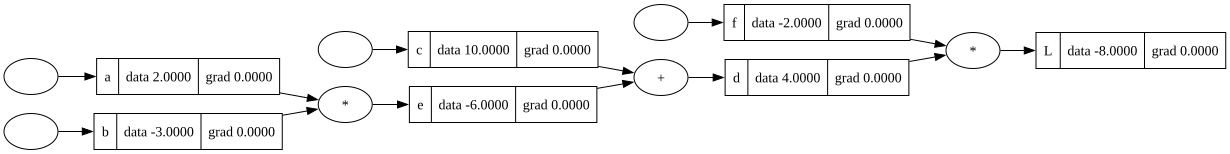

In [15]:
draw_dot(L)

In [16]:
a.data += 0.01* a.grad
b.data += 0.01* b.grad
c.data += 0.01*c.grad
f.data += 0.01*f.grad

e = a * b
d = e + c
L = d * f

print(L.data)

-7.9772


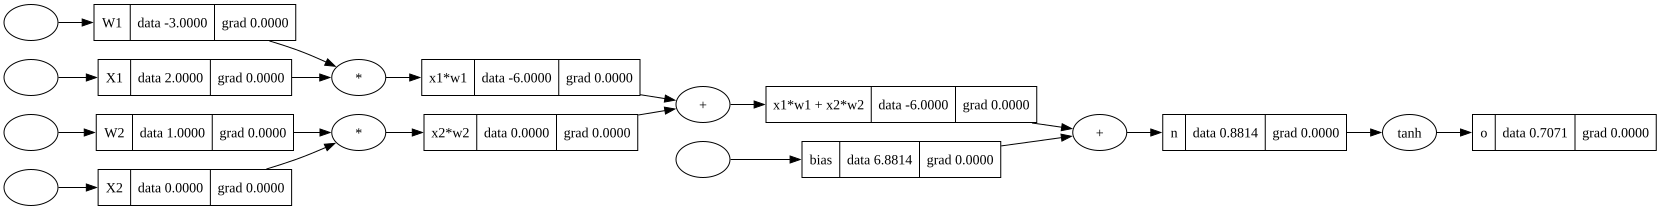

In [53]:
#inputs
x1 = Value(2.0 , _label = 'X1')
x2 = Value(0.0 , _label = 'X2')
#weights w1 , w2
weights1 = Value(-3.0 , _label  = 'W1')
weights2 = Value(1.0 , _label = 'W2' )
bias = Value( 6.8813735870195432 , _label = 'bias')
x1w1 = x1*weights1; x1w1._label = "x1*w1"
x2w2 = x2*weights2; x2w2._label = "x2*w2"
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2._label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + bias; n._label = 'n'
o = n.tanh() ; o._label = 'o'
draw_dot(o)

In [61]:
o.grad = 1.0
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

for node in reversed(topo):
    node._backward()

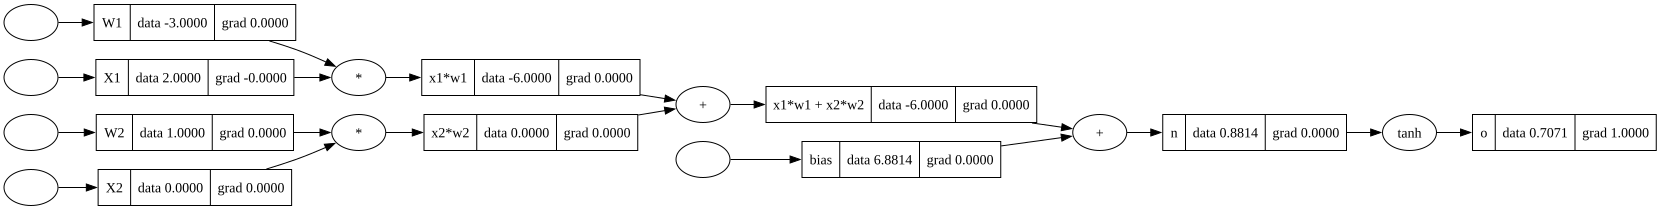

In [66]:
draw_dot(o)

In [44]:
n = x1w1x2w2 + bias
o = n.tanh()
o.grad = 1

In [45]:
1 - o.data**2

0.4999999999999999

o = tanh(N)
do/dn = 1- o.data**2

In [46]:
n.grad = 0.5

In [47]:
bias.grad = n.grad
x1w1x2w2.grad = n.grad

In [48]:
x1w1.grad = n.grad
x2w2.grad = n.grad

In [63]:
x1.grad = -3*n.grad
x2.grad = 1*n.grad
#weights w1 , w2
weights1.grad = 2*n.grad
weights2.grad = 0*n.grad


In [4]:
class Neuron:
    def __init__(self , nin): #nin is the number of inputs
        self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
        self.b = Value(random.uniform(-1,1))
    def __call__(self, x):#
        act = sum(wi*xi for wi, xi in zip(self.w,x), self.b)
        out = act.tanh()
        return out

class layer:
    def __init__(self,nin,nout): #what is n out is how many layers you want 
        self.neurons = [Neuron(nin) for _ in range(nout)]
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs 
        